In [1]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 1: ENVIRONMENT SETUP AND GPU VERIFICATION
# ================================================================
# Summary:
# 1. Import libraries required for diffusion modeling.
# 2. Verify GPU availability and select the compute device.
# 3. Set random seeds for reproducible experiments.
# 4. Initialize a timer to track experiment execution time.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Import required libraries
# ------------------------------------------------
import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# ------------------------------------------------
# BLOCK 2: Configure reproducibility
# ------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------
# BLOCK 3: Detect GPU and select device
# ------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

gpu_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "Not available"
)

# ------------------------------------------------
# BLOCK 4: Initialize execution timer
# ------------------------------------------------
experiment_start_time = time.time()

# ------------------------------------------------
# BLOCK 5: Display environment verification
# ------------------------------------------------
print("=" * 65)
print("HOMEWORK 8 — STEP 1: ENVIRONMENT VERIFICATION")
print("=" * 65)

print(f"PyTorch Version       : {torch.__version__}")
print(f"Torchvision Available : Yes")
print(f"CUDA Available        : {torch.cuda.is_available()}")
print(f"Selected Device       : {device}")
print(f"GPU Name              : {gpu_name}")
print(f"Random Seed           : {SEED}")

print("-" * 65)

if device.type == "cuda":
    print("PASS: GPU environment ready for diffusion training.")
else:
    print("WARNING: GPU not detected. Enable GPU in Colab runtime.")

print("=" * 65)
print("STEP 1 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 1: ENVIRONMENT VERIFICATION
PyTorch Version       : 2.11.0+cu130
Torchvision Available : Yes
CUDA Available        : True
Selected Device       : cuda
GPU Name              : Tesla T4
Random Seed           : 42
-----------------------------------------------------------------
PASS: GPU environment ready for diffusion training.
STEP 1 COMPLETE


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

100%|██████████| 9.91M/9.91M [00:00<00:00, 55.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.81MB/s]


HOMEWORK 8 — STEP 2: MNIST DATASET VERIFICATION
Dataset Name          : MNIST
Training Samples      : 60,000
Batch Size            : 128
Number of Batches     : 469
Image Batch Shape     : (128, 1, 28, 28)
Image Minimum Value   : -1.0000
Image Maximum Value   : 1.0000
Image Data Type       : torch.float32


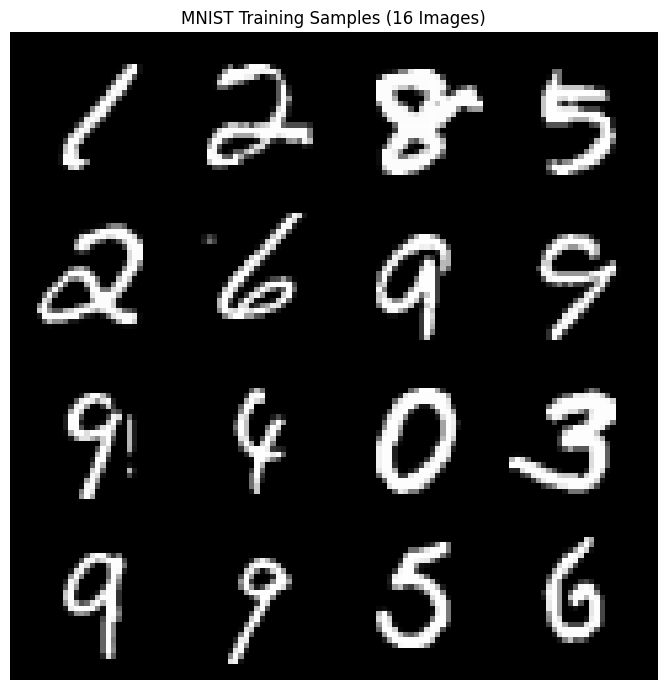

-----------------------------------------------------------------
PASS: MNIST dataset loaded successfully.
PASS: Image dimensions verified (1, 28, 28).
PASS: Pixel normalization verified [-1, 1].
PASS: DataLoader ready for diffusion training.
STEP 2 COMPLETE


In [3]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 2: MNIST DATASET LOADING AND VISUALIZATION
# ================================================================
# Summary:
# 1. Download and load the MNIST training dataset.
# 2. Normalize pixel values to the range [-1, 1].
# 3. Create a DataLoader with batch size 128.
# 4. Verify image dimensions and dataset properties.
# 5. Visualize sample MNIST handwritten digits.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Define dataset transformations
# ------------------------------------------------
# Convert images to tensors and normalize [0, 1] to [-1, 1].

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# ------------------------------------------------
# BLOCK 2: Download and load MNIST training dataset
# ------------------------------------------------
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# ------------------------------------------------
# BLOCK 3: Create training DataLoader
# ------------------------------------------------
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------
# BLOCK 4: Retrieve and verify one training batch
# ------------------------------------------------
images, labels = next(iter(train_loader))

print("=" * 65)
print("HOMEWORK 8 — STEP 2: MNIST DATASET VERIFICATION")
print("=" * 65)

print(f"Dataset Name          : MNIST")
print(f"Training Samples      : {len(train_dataset):,}")
print(f"Batch Size            : {BATCH_SIZE}")
print(f"Number of Batches     : {len(train_loader)}")
print(f"Image Batch Shape     : {tuple(images.shape)}")
print(f"Image Minimum Value   : {images.min().item():.4f}")
print(f"Image Maximum Value   : {images.max().item():.4f}")
print(f"Image Data Type       : {images.dtype}")

# ------------------------------------------------
# BLOCK 5: Visualize sample MNIST digits
# ------------------------------------------------
# Convert normalized images back to [0, 1] for display.

sample_images = images[:16] * 0.5 + 0.5

grid = make_grid(
    sample_images,
    nrow=4,
    padding=2
)

plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("MNIST Training Samples (16 Images)")
plt.axis("off")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# BLOCK 6: Validate dataset configuration
# ------------------------------------------------
assert len(train_dataset) == 60000, "Unexpected dataset size."
assert images.shape[1:] == (1, 28, 28), "Invalid image dimensions."
assert images.min() >= -1.0 and images.max() <= 1.0, \
    "Image normalization failed."

print("-" * 65)
print("PASS: MNIST dataset loaded successfully.")
print("PASS: Image dimensions verified (1, 28, 28).")
print("PASS: Pixel normalization verified [-1, 1].")
print("PASS: DataLoader ready for diffusion training.")
print("=" * 65)
print("STEP 2 COMPLETE")
print("=" * 65)


In [4]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 3: FORWARD DIFFUSION NOISE SCHEDULE
# ================================================================
# Summary:
# 1. Configure 100 diffusion timesteps.
# 2. Create a linear beta noise schedule.
# 3. Compute alpha and cumulative alpha values.
# 4. Implement the forward diffusion equation.
# 5. Verify the diffusion schedule and output shapes.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Configure diffusion parameters
# ------------------------------------------------
T = 100

BETA_START = 0.0001
BETA_END = 0.02

# ------------------------------------------------
# BLOCK 2: Generate linear beta schedule
# ------------------------------------------------
betas = torch.linspace(
    BETA_START,
    BETA_END,
    T,
    device=device
)

# ------------------------------------------------
# BLOCK 3: Calculate alpha values
# ------------------------------------------------
alphas = 1.0 - betas

# Cumulative product of alpha values
alpha_bars = torch.cumprod(alphas, dim=0)

# ------------------------------------------------
# BLOCK 4: Precompute forward diffusion coefficients
# ------------------------------------------------
sqrt_alpha_bars = torch.sqrt(alpha_bars)

sqrt_one_minus_alpha_bars = torch.sqrt(
    1.0 - alpha_bars
)

# ------------------------------------------------
# BLOCK 5: Implement forward diffusion function
# ------------------------------------------------
def forward_diffusion(x0, t, noise=None):
    """
    Adds Gaussian noise to clean images at timestep t.

    Args:
        x0: Clean images [B, 1, 28, 28].
        t: Diffusion timesteps [B].
        noise: Optional Gaussian noise tensor.

    Returns:
        xt: Noisy images.
        noise: Gaussian noise used.
    """

    # Generate Gaussian noise if not supplied
    if noise is None:
        noise = torch.randn_like(x0)

    # Extract coefficients for each image's timestep
    sqrt_alpha_bar_t = sqrt_alpha_bars[t].view(-1, 1, 1, 1)

    sqrt_one_minus_alpha_bar_t = (
        sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    )

    # Apply the forward diffusion equation
    xt = (
        sqrt_alpha_bar_t * x0
        + sqrt_one_minus_alpha_bar_t * noise
    )

    return xt, noise

# ------------------------------------------------
# BLOCK 6: Verify diffusion configuration
# ------------------------------------------------
print("=" * 65)
print("HOMEWORK 8 — STEP 3: FORWARD DIFFUSION VERIFICATION")
print("=" * 65)

print(f"Diffusion Steps       : {T}")
print(f"Beta Start            : {betas[0].item():.6f}")
print(f"Beta End              : {betas[-1].item():.6f}")
print(f"Alpha Bar at t=0      : {alpha_bars[0].item():.6f}")
print(f"Alpha Bar at t=99     : {alpha_bars[-1].item():.6f}")

# ------------------------------------------------
# BLOCK 7: Test forward diffusion on MNIST images
# ------------------------------------------------
test_images = images[:8].to(device)

test_timesteps = torch.full(
    (8,),
    50,
    dtype=torch.long,
    device=device
)

noisy_images, sampled_noise = forward_diffusion(
    test_images,
    test_timesteps
)

print("-" * 65)
print(f"Original Image Shape  : {tuple(test_images.shape)}")
print(f"Noisy Image Shape     : {tuple(noisy_images.shape)}")
print(f"Noise Tensor Shape    : {tuple(sampled_noise.shape)}")

# ------------------------------------------------
# BLOCK 8: Validate outputs
# ------------------------------------------------
assert len(betas) == T
assert torch.all(betas[1:] > betas[:-1])
assert torch.all(alpha_bars[1:] < alpha_bars[:-1])
assert noisy_images.shape == test_images.shape
assert sampled_noise.shape == test_images.shape
assert torch.isfinite(noisy_images).all()

print("-" * 65)
print("PASS: Linear beta schedule verified.")
print("PASS: Cumulative alpha values verified.")
print("PASS: Forward diffusion equation executed.")
print("PASS: Noisy image dimensions verified.")
print("=" * 65)
print("STEP 3 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 3: FORWARD DIFFUSION VERIFICATION
Diffusion Steps       : 100
Beta Start            : 0.000100
Beta End              : 0.020000
Alpha Bar at t=0      : 0.999900
Alpha Bar at t=99     : 0.363563
-----------------------------------------------------------------
Original Image Shape  : (8, 1, 28, 28)
Noisy Image Shape     : (8, 1, 28, 28)
Noise Tensor Shape    : (8, 1, 28, 28)
-----------------------------------------------------------------
PASS: Linear beta schedule verified.
PASS: Cumulative alpha values verified.
PASS: Forward diffusion equation executed.
PASS: Noisy image dimensions verified.
STEP 3 COMPLETE


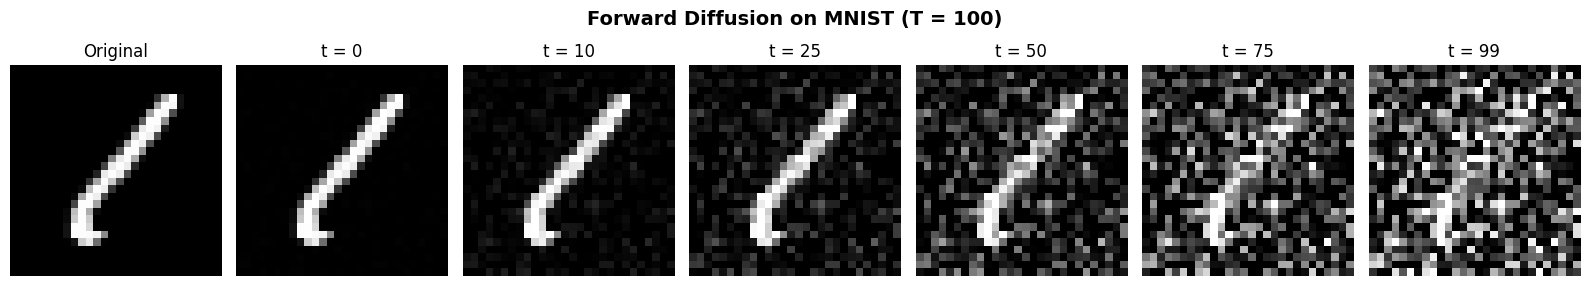

HOMEWORK 8 — STEP 4: VISUALIZATION VERIFICATION
Original Image Shape  : (1, 1, 28, 28)
Timesteps Visualized  : [0, 10, 25, 50, 75, 99]
Generated Images      : 6
Visualization Saved   : HW8_Results/forward_diffusion.png
-----------------------------------------------------------------
PASS: Original MNIST image visualized.
PASS: Forward diffusion applied at six timesteps.
PASS: Visualization saved successfully.
STEP 4 COMPLETE — PART A


In [5]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 4: FORWARD DIFFUSION VISUALIZATION
# ================================================================
# Summary:
# 1. Select one MNIST handwritten digit.
# 2. Define six diffusion timesteps.
# 3. Apply Gaussian noise using forward diffusion.
# 4. Visualize the progressive corruption of the digit.
# 5. Save the visualization for assignment submission.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Select one MNIST image
# ------------------------------------------------
original_image = images[0:1].to(device)

# ------------------------------------------------
# BLOCK 2: Define visualization timesteps
# ------------------------------------------------
timesteps_to_show = [0, 10, 25, 50, 75, 99]

# ------------------------------------------------
# BLOCK 3: Generate one Gaussian noise tensor
# ------------------------------------------------
# Reuse the same noise to make timestep comparisons consistent.
fixed_noise = torch.randn_like(original_image)

# ------------------------------------------------
# BLOCK 4: Apply forward diffusion
# ------------------------------------------------
diffused_images = []

for timestep in timesteps_to_show:

    t = torch.tensor(
        [timestep],
        dtype=torch.long,
        device=device
    )

    noisy_image, _ = forward_diffusion(
        original_image,
        t,
        noise=fixed_noise
    )

    diffused_images.append(noisy_image.detach().cpu())

# ------------------------------------------------
# BLOCK 5: Visualize original and noisy images
# ------------------------------------------------
fig, axes = plt.subplots(1, 7, figsize=(16, 3))

# Display original image
axes[0].imshow(
    original_image[0, 0].cpu().numpy(),
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[0].set_title("Original")
axes[0].axis("off")

# Display noisy images at selected timesteps
for idx, (timestep, noisy_image) in enumerate(
    zip(timesteps_to_show, diffused_images)
):
    axes[idx + 1].imshow(
        noisy_image[0, 0].numpy(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    axes[idx + 1].set_title(f"t = {timestep}")
    axes[idx + 1].axis("off")

plt.suptitle(
    "Forward Diffusion on MNIST (T = 100)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------
# BLOCK 6: Save visualization
# ------------------------------------------------
os.makedirs("HW8_Results", exist_ok=True)

output_path = "HW8_Results/forward_diffusion.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# BLOCK 7: Verify generated visualization
# ------------------------------------------------
assert len(diffused_images) == 6
assert all(img.shape == (1, 1, 28, 28)
           for img in diffused_images)
assert os.path.exists(output_path)

print("=" * 65)
print("HOMEWORK 8 — STEP 4: VISUALIZATION VERIFICATION")
print("=" * 65)

print(f"Original Image Shape  : {tuple(original_image.shape)}")
print(f"Timesteps Visualized  : {timesteps_to_show}")
print(f"Generated Images      : {len(diffused_images)}")
print(f"Visualization Saved   : {output_path}")

print("-" * 65)
print("PASS: Original MNIST image visualized.")
print("PASS: Forward diffusion applied at six timesteps.")
print("PASS: Visualization saved successfully.")
print("=" * 65)
print("STEP 4 COMPLETE — PART A")
print("=" * 65)


In [6]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 5: BUILD TIMESTEP-CONDITIONED CNN NOISE PREDICTOR
# ================================================================
# Summary:
# 1. Define a CNN with six convolutional layers.
# 2. Add nonlinear ReLU activation functions.
# 3. Implement timestep embedding and conditioning.
# 4. Preserve input and output image dimensions.
# 5. Verify model architecture and forward propagation.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Define CNN noise prediction network
# ------------------------------------------------
class MiniDiffusionCNN(nn.Module):

    def __init__(self, timesteps=100):
        super().__init__()

        # Embed each diffusion timestep into 64 features
        self.time_embedding = nn.Embedding(timesteps, 64)

        # Project timestep embedding to feature maps
        self.time_projection = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU()
        )

        # Six convolutional layers with nonlinear activations
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(64, 1, kernel_size=3, padding=1)

    # ------------------------------------------------
    # BLOCK 2: Define forward propagation
    # ------------------------------------------------
    def forward(self, x, t):

        # Convert timestep indices into embeddings
        t_emb = self.time_embedding(t)
        t_emb = self.time_projection(t_emb)

        # Reshape for spatial broadcasting
        t_emb = t_emb[:, :, None, None]

        # Apply convolutional layers with ReLU
        h = F.relu(self.conv1(x))

        # Inject timestep information into feature maps
        h = h + t_emb

        h = F.relu(self.conv2(h))
        h = F.relu(self.conv3(h))
        h = F.relu(self.conv4(h))
        h = F.relu(self.conv5(h))

        # Predict Gaussian noise (same shape as input)
        output = self.conv6(h)

        return output

# ------------------------------------------------
# BLOCK 3: Initialize model on selected device
# ------------------------------------------------
model = MiniDiffusionCNN(timesteps=T).to(device)

# ------------------------------------------------
# BLOCK 4: Count trainable parameters
# ------------------------------------------------
total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

conv_layers = sum(
    isinstance(layer, nn.Conv2d)
    for layer in model.modules()
)

# ------------------------------------------------
# BLOCK 5: Test model forward propagation
# ------------------------------------------------
test_input = torch.randn(
    8, 1, 28, 28,
    device=device
)

test_t = torch.randint(
    0, T, (8,),
    device=device
)

with torch.no_grad():
    predicted_noise = model(test_input, test_t)

# ------------------------------------------------
# BLOCK 6: Verify model requirements
# ------------------------------------------------
assert conv_layers >= 4, "CNN requires at least 4 convolutional layers."
assert predicted_noise.shape == test_input.shape, \
    "Output shape must match input shape."
assert torch.isfinite(predicted_noise).all()

print("=" * 65)
print("HOMEWORK 8 — STEP 5: CNN ARCHITECTURE VERIFICATION")
print("=" * 65)

print(f"Model Name            : MiniDiffusionCNN")
print(f"Convolutional Layers  : {conv_layers}")
print(f"Activation Function   : ReLU")
print(f"Timestep Conditioning : Embedding + Projection")
print(f"Total Parameters      : {total_parameters:,}")
print(f"Trainable Parameters  : {trainable_parameters:,}")
print(f"Input Shape           : {tuple(test_input.shape)}")
print(f"Output Shape          : {tuple(predicted_noise.shape)}")
print(f"Selected Device       : {device}")

print("-" * 65)
print("PASS: CNN contains at least 4 convolutional layers.")
print("PASS: Nonlinear activations implemented.")
print("PASS: Timestep conditioning implemented.")
print("PASS: Output dimensions match input dimensions.")
print("PASS: Forward propagation successful.")
print("=" * 65)
print("STEP 5 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 5: CNN ARCHITECTURE VERIFICATION
Model Name            : MiniDiffusionCNN
Convolutional Layers  : 6
Activation Function   : ReLU
Timestep Conditioning : Embedding + Projection
Total Parameters      : 343,937
Trainable Parameters  : 343,937
Input Shape           : (8, 1, 28, 28)
Output Shape          : (8, 1, 28, 28)
Selected Device       : cuda
-----------------------------------------------------------------
PASS: CNN contains at least 4 convolutional layers.
PASS: Nonlinear activations implemented.
PASS: Timestep conditioning implemented.
PASS: Output dimensions match input dimensions.
PASS: Forward propagation successful.
STEP 5 COMPLETE


In [7]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 6: DDPM TRAINING CONFIGURATION AND LOSS VERIFICATION
# ================================================================
# Summary:
# 1. Configure training hyperparameters.
# 2. Initialize the Adam optimizer and MSE loss.
# 3. Sample random diffusion timesteps.
# 4. Generate noisy MNIST images.
# 5. Predict Gaussian noise using the CNN.
# 6. Verify loss calculation and gradient propagation.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Configure training hyperparameters
# ------------------------------------------------
EPOCHS = 50
LEARNING_RATE = 1e-3

# ------------------------------------------------
# BLOCK 2: Initialize optimizer and loss function
# ------------------------------------------------
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.MSELoss()

# ------------------------------------------------
# BLOCK 3: Retrieve one training batch
# ------------------------------------------------
train_images, _ = next(iter(train_loader))

train_images = train_images.to(
    device,
    non_blocking=True
)

batch_size = train_images.shape[0]

# ------------------------------------------------
# BLOCK 4: Sample random diffusion timesteps
# ------------------------------------------------
# Each image receives a randomly selected timestep.
t = torch.randint(
    low=0,
    high=T,
    size=(batch_size,),
    device=device
)

# ------------------------------------------------
# BLOCK 5: Apply forward diffusion
# ------------------------------------------------
# Generate noisy images and retain the true noise.
noisy_images, true_noise = forward_diffusion(
    train_images,
    t
)

# ------------------------------------------------
# BLOCK 6: Predict noise using CNN
# ------------------------------------------------
model.train()

predicted_noise = model(
    noisy_images,
    t
)

# ------------------------------------------------
# BLOCK 7: Calculate noise-prediction loss
# ------------------------------------------------
# DDPM objective: MSE between true and predicted noise.
loss = criterion(
    predicted_noise,
    true_noise
)

# ------------------------------------------------
# BLOCK 8: Verify backward propagation
# ------------------------------------------------
# Compute gradients without updating model parameters.
optimizer.zero_grad(set_to_none=True)

loss.backward()

gradient_count = sum(
    p.grad is not None
    for p in model.parameters()
    if p.requires_grad
)

gradient_norm = sum(
    p.grad.detach().norm().item() ** 2
    for p in model.parameters()
    if p.grad is not None
) ** 0.5

# ------------------------------------------------
# BLOCK 9: Validate training configuration
# ------------------------------------------------
assert EPOCHS == 50
assert LEARNING_RATE > 0
assert predicted_noise.shape == true_noise.shape
assert torch.isfinite(loss).item()
assert gradient_count > 0
assert gradient_norm > 0

print("=" * 65)
print("HOMEWORK 8 — STEP 6: TRAINING CONFIGURATION VERIFICATION")
print("=" * 65)

print(f"Training Epochs       : {EPOCHS}")
print(f"Batch Size            : {batch_size}")
print(f"Learning Rate         : {LEARNING_RATE}")
print(f"Optimizer             : Adam")
print(f"Loss Function         : Mean Squared Error")
print(f"Diffusion Steps       : {T}")
print(f"Input Image Shape     : {tuple(train_images.shape)}")
print(f"Noisy Image Shape     : {tuple(noisy_images.shape)}")
print(f"Predicted Noise Shape : {tuple(predicted_noise.shape)}")
print(f"True Noise Shape      : {tuple(true_noise.shape)}")
print(f"Initial Batch Loss    : {loss.item():.6f}")
print(f"Parameters with Grads : {gradient_count}")
print(f"Gradient Norm         : {gradient_norm:.6f}")

print("-" * 65)
print("PASS: Training hyperparameters configured.")
print("PASS: Random diffusion timesteps sampled.")
print("PASS: Forward diffusion applied successfully.")
print("PASS: Noise-prediction MSE loss calculated.")
print("PASS: Backward propagation verified.")
print("=" * 65)
print("STEP 6 COMPLETE")
print("=" * 65)

# ------------------------------------------------
# BLOCK 10: Clear test gradients before training
# ------------------------------------------------
optimizer.zero_grad(set_to_none=True)


HOMEWORK 8 — STEP 6: TRAINING CONFIGURATION VERIFICATION
Training Epochs       : 50
Batch Size            : 128
Learning Rate         : 0.001
Optimizer             : Adam
Loss Function         : Mean Squared Error
Diffusion Steps       : 100
Input Image Shape     : (128, 1, 28, 28)
Noisy Image Shape     : (128, 1, 28, 28)
Predicted Noise Shape : (128, 1, 28, 28)
True Noise Shape      : (128, 1, 28, 28)
Initial Batch Loss    : 1.000446
Parameters with Grads : 15
Gradient Norm         : 0.136050
-----------------------------------------------------------------
PASS: Training hyperparameters configured.
PASS: Random diffusion timesteps sampled.
PASS: Forward diffusion applied successfully.
PASS: Noise-prediction MSE loss calculated.
PASS: Backward propagation verified.
STEP 6 COMPLETE


In [8]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 7: TRAIN MINI DDPM FOR 50 EPOCHS
# ================================================================
# Summary:
# 1. Train the CNN noise predictor for 50 epochs.
# 2. Sample random diffusion timesteps for each batch.
# 3. Generate noisy MNIST images using forward diffusion.
# 4. Minimize MSE between predicted and actual noise.
# 5. Track epoch-wise loss and GPU training time.
# 6. Save model checkpoints and training history.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Initialize training history and timer
# ------------------------------------------------
training_losses = []
epoch_times = []

os.makedirs("HW8_Results", exist_ok=True)

# Synchronize GPU before starting the timer
if device.type == "cuda":
    torch.cuda.synchronize()

training_start_time = time.time()

print("=" * 65)
print("HOMEWORK 8 — STEP 7: DDPM MODEL TRAINING")
print("=" * 65)
print(f"Training Epochs       : {EPOCHS}")
print(f"Training Samples      : {len(train_dataset):,}")
print(f"Batches per Epoch     : {len(train_loader)}")
print(f"Batch Size            : {BATCH_SIZE}")
print(f"Optimizer             : Adam")
print(f"Learning Rate         : {LEARNING_RATE}")
print(f"Device                : {device}")
print("-" * 65)

# ------------------------------------------------
# BLOCK 2: Begin training loop
# ------------------------------------------------
model.train()

for epoch in range(EPOCHS):

    epoch_start_time = time.time()
    running_loss = 0.0
    samples_processed = 0

    # --------------------------------------------
    # BLOCK 3: Iterate through MNIST training batches
    # --------------------------------------------
    for batch_images, _ in train_loader:

        # Transfer images to GPU
        batch_images = batch_images.to(
            device,
            non_blocking=True
        )

        current_batch_size = batch_images.shape[0]

        # ----------------------------------------
        # BLOCK 4: Sample random diffusion timesteps
        # ----------------------------------------
        t = torch.randint(
            low=0,
            high=T,
            size=(current_batch_size,),
            device=device
        )

        # ----------------------------------------
        # BLOCK 5: Generate noisy images
        # ----------------------------------------
        noisy_images, true_noise = forward_diffusion(
            batch_images,
            t
        )

        # ----------------------------------------
        # BLOCK 6: Predict noise and calculate MSE
        # ----------------------------------------
        optimizer.zero_grad(set_to_none=True)

        predicted_noise = model(
            noisy_images,
            t
        )

        loss = criterion(
            predicted_noise,
            true_noise
        )

        # ----------------------------------------
        # BLOCK 7: Backpropagation and optimization
        # ----------------------------------------
        loss.backward()

        # Clip gradients to improve training stability
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        # Accumulate sample-weighted training loss
        running_loss += loss.item() * current_batch_size
        samples_processed += current_batch_size

    # --------------------------------------------
    # BLOCK 8: Calculate epoch statistics
    # --------------------------------------------
    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_loss = running_loss / samples_processed
    epoch_duration = time.time() - epoch_start_time

    training_losses.append(epoch_loss)
    epoch_times.append(epoch_duration)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Loss: {epoch_loss:.6f} "
        f"| Time: {epoch_duration:.2f}s",
        flush=True
    )

    # --------------------------------------------
    # BLOCK 9: Save checkpoint every 10 epochs
    # --------------------------------------------
    if (epoch + 1) % 10 == 0:

        checkpoint_path = (
            f"HW8_Results/ddpm_checkpoint_epoch_{epoch + 1}.pt"
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "training_losses": training_losses,
            "epoch_times": epoch_times,
            "seed": SEED,
            "diffusion_steps": T,
            "learning_rate": LEARNING_RATE
        }, checkpoint_path)

        print(f"Checkpoint Saved: {checkpoint_path}")

# ------------------------------------------------
# BLOCK 10: Calculate total training time
# ------------------------------------------------
if device.type == "cuda":
    torch.cuda.synchronize()

total_training_time = time.time() - training_start_time

# ------------------------------------------------
# BLOCK 11: Save final trained model
# ------------------------------------------------
final_model_path = "HW8_Results/ddpm_final_model.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": EPOCHS,
    "training_losses": training_losses,
    "epoch_times": epoch_times,
    "total_training_time": total_training_time,
    "diffusion_steps": T,
    "seed": SEED
}, final_model_path)

# Save training history separately
np.save(
    "HW8_Results/training_losses.npy",
    np.array(training_losses)
)

# ------------------------------------------------
# BLOCK 12: Verify training completion
# ------------------------------------------------
assert len(training_losses) == EPOCHS
assert np.isfinite(training_losses).all()
assert os.path.exists(final_model_path)

print("=" * 65)
print("HOMEWORK 8 — STEP 7: TRAINING VERIFICATION")
print("=" * 65)

print(f"Completed Epochs      : {len(training_losses)}")
print(f"Initial Epoch Loss    : {training_losses[0]:.6f}")
print(f"Final Epoch Loss      : {training_losses[-1]:.6f}")
print(f"Best Epoch Loss       : {min(training_losses):.6f}")
print(f"Total Training Time   : {total_training_time:.2f} seconds")
print(f"Training Time (Hours) : {total_training_time / 3600:.4f}")
print(f"Final Model Saved     : {final_model_path}")

print("-" * 65)
print("PASS: All 50 training epochs completed.")
print("PASS: Training loss history recorded.")
print("PASS: Model checkpoints saved.")
print("PASS: Final trained model saved.")
print("=" * 65)
print("STEP 7 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 7: DDPM MODEL TRAINING
Training Epochs       : 50
Training Samples      : 60,000
Batches per Epoch     : 469
Batch Size            : 128
Optimizer             : Adam
Learning Rate         : 0.001
Device                : cuda
-----------------------------------------------------------------
Epoch [01/50] | Loss: 0.155908 | Time: 19.51s
Epoch [02/50] | Loss: 0.079759 | Time: 19.84s
Epoch [03/50] | Loss: 0.072875 | Time: 20.61s
Epoch [04/50] | Loss: 0.070430 | Time: 20.50s
Epoch [05/50] | Loss: 0.068887 | Time: 20.18s
Epoch [06/50] | Loss: 0.066684 | Time: 20.07s
Epoch [07/50] | Loss: 0.065556 | Time: 20.13s
Epoch [08/50] | Loss: 0.064829 | Time: 20.22s
Epoch [09/50] | Loss: 0.064451 | Time: 20.19s
Epoch [10/50] | Loss: 0.063245 | Time: 20.16s
Checkpoint Saved: HW8_Results/ddpm_checkpoint_epoch_10.pt
Epoch [11/50] | Loss: 0.063579 | Time: 20.13s
Epoch [12/50] | Loss: 0.062954 | Time: 20.10s
Epoch [13/50] | Loss: 0.062654 | Time: 20.09s
Epoch [14/50] | Loss: 0.062062 | Ti

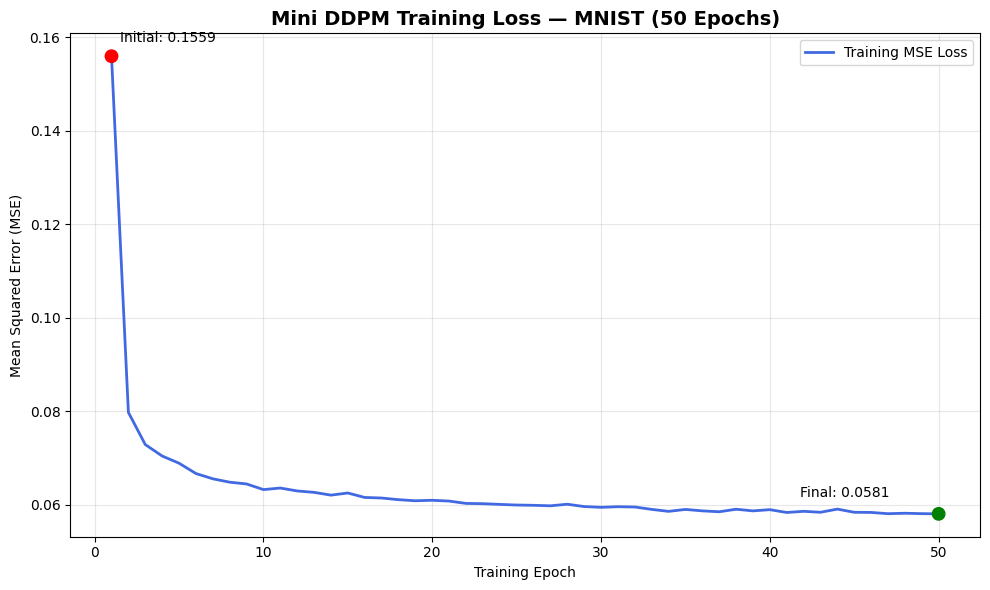

HOMEWORK 8 — STEP 8: TRAINING LOSS VERIFICATION
Total Epochs          : 50
Initial Epoch Loss    : 0.155908
Final Epoch Loss      : 0.058062
Best Epoch Loss       : 0.058062
Best Epoch            : 50
Loss Reduction        : 62.76%
Training Time         : 1002.49 seconds
Loss Plot Saved       : HW8_Results/ddpm_training_loss.png
-----------------------------------------------------------------
PASS: All 50 epoch losses recorded.
PASS: Training loss decreased.
PASS: Loss visualization generated.
PASS: Training loss plot saved.
STEP 8 COMPLETE — PART B


In [9]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 8: TRAINING LOSS VISUALIZATION AND VERIFICATION
# ================================================================
# Summary:
# 1. Retrieve training loss history from 50 epochs.
# 2. Plot epoch-wise MSE training loss.
# 3. Highlight initial and final training losses.
# 4. Save the loss visualization for submission.
# 5. Verify training convergence and saved output.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Prepare training loss data
# ------------------------------------------------
epochs = np.arange(1, len(training_losses) + 1)

loss_values = np.array(training_losses)

initial_loss = loss_values[0]
final_loss = loss_values[-1]
best_loss = np.min(loss_values)
best_epoch = np.argmin(loss_values) + 1

# ------------------------------------------------
# BLOCK 2: Calculate training loss improvement
# ------------------------------------------------
loss_reduction = (
    (initial_loss - final_loss) / initial_loss
) * 100

# ------------------------------------------------
# BLOCK 3: Create training loss plot
# ------------------------------------------------
plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    loss_values,
    linewidth=2,
    color="royalblue",
    label="Training MSE Loss"
)

# Highlight initial and final losses
plt.scatter(
    [1, 50],
    [initial_loss, final_loss],
    color=["red", "green"],
    s=80,
    zorder=5
)

plt.annotate(
    f"Initial: {initial_loss:.4f}",
    xy=(1, initial_loss),
    xytext=(6, 10),
    textcoords="offset points"
)

plt.annotate(
    f"Final: {final_loss:.4f}",
    xy=(50, final_loss),
    xytext=(-100, 12),
    textcoords="offset points"
)

# ------------------------------------------------
# BLOCK 4: Configure plot appearance
# ------------------------------------------------
plt.title(
    "Mini DDPM Training Loss — MNIST (50 Epochs)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Training Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# ------------------------------------------------
# BLOCK 5: Save training loss visualization
# ------------------------------------------------
loss_plot_path = "HW8_Results/ddpm_training_loss.png"

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# BLOCK 6: Verify training convergence
# ------------------------------------------------
assert len(loss_values) == 50
assert np.isfinite(loss_values).all()
assert final_loss < initial_loss
assert os.path.exists(loss_plot_path)

print("=" * 65)
print("HOMEWORK 8 — STEP 8: TRAINING LOSS VERIFICATION")
print("=" * 65)

print(f"Total Epochs          : {len(loss_values)}")
print(f"Initial Epoch Loss    : {initial_loss:.6f}")
print(f"Final Epoch Loss      : {final_loss:.6f}")
print(f"Best Epoch Loss       : {best_loss:.6f}")
print(f"Best Epoch            : {best_epoch}")
print(f"Loss Reduction        : {loss_reduction:.2f}%")
print(f"Training Time         : {total_training_time:.2f} seconds")
print(f"Loss Plot Saved       : {loss_plot_path}")

print("-" * 65)
print("PASS: All 50 epoch losses recorded.")
print("PASS: Training loss decreased.")
print("PASS: Loss visualization generated.")
print("PASS: Training loss plot saved.")
print("=" * 65)
print("STEP 8 COMPLETE — PART B")
print("=" * 65)


In [10]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 9: IMPLEMENT DDPM REVERSE SAMPLING
# ================================================================
# Summary:
# 1. Configure DDPM reverse diffusion coefficients.
# 2. Initialize sampling from standard Gaussian noise.
# 3. Predict noise using the trained CNN.
# 4. Apply the DDPM reverse sampling equation.
# 5. Perform all 100 reverse diffusion steps.
# 6. Verify generated image dimensions and values.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Prepare DDPM reverse diffusion coefficients
# ------------------------------------------------
# Alpha bar at the previous timestep.
# For t=0, use alpha_bar_previous=1.

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

# Posterior variance for DDPM sampling
posterior_variance = (
    betas * (1.0 - alpha_bars_prev)
    / (1.0 - alpha_bars)
)

# ------------------------------------------------
# BLOCK 2: Define DDPM reverse sampling function
# ------------------------------------------------
@torch.no_grad()
def ddpm_sample(model, num_images=16):
    """
    Generate images using DDPM reverse sampling.

    Args:
        model: Trained noise-prediction CNN.
        num_images: Number of images to generate.

    Returns:
        Generated MNIST-like images [N, 1, 28, 28].
    """

    # Set model to evaluation mode
    model.eval()

    # --------------------------------------------
    # BLOCK 3: Initialize Gaussian noise
    # --------------------------------------------
    x = torch.randn(
        num_images,
        1,
        28,
        28,
        device=device
    )

    # --------------------------------------------
    # BLOCK 4: Reverse diffusion loop
    # --------------------------------------------
    for timestep in reversed(range(T)):

        # Create timestep tensor for all images
        t = torch.full(
            (num_images,),
            timestep,
            dtype=torch.long,
            device=device
        )

        # Predict noise using trained CNN
        predicted_noise = model(x, t)

        # ----------------------------------------
        # BLOCK 5: Calculate reverse diffusion mean
        # ----------------------------------------
        alpha_t = alphas[timestep]
        alpha_bar_t = alpha_bars[timestep]
        beta_t = betas[timestep]

        mean = (
            x - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            ) * predicted_noise
        ) / torch.sqrt(alpha_t)

        # ----------------------------------------
        # BLOCK 6: Add posterior Gaussian noise
        # ----------------------------------------
        if timestep > 0:

            noise = torch.randn_like(x)

            variance = posterior_variance[timestep]

            x = mean + torch.sqrt(variance) * noise

        else:
            # Final step: no additional noise
            x = mean

    return x

# ------------------------------------------------
# BLOCK 7: Generate sample images using DDPM
# ------------------------------------------------
NUM_GENERATED_IMAGES = 16

if device.type == "cuda":
    torch.cuda.synchronize()

ddpm_start_time = time.time()

ddpm_generated_images = ddpm_sample(
    model,
    num_images=NUM_GENERATED_IMAGES
)

if device.type == "cuda":
    torch.cuda.synchronize()

ddpm_sampling_time = time.time() - ddpm_start_time

# ------------------------------------------------
# BLOCK 8: Verify DDPM-generated images
# ------------------------------------------------
assert ddpm_generated_images.shape == (
    NUM_GENERATED_IMAGES, 1, 28, 28
)

assert torch.isfinite(ddpm_generated_images).all()

print("=" * 65)
print("HOMEWORK 8 — STEP 9: DDPM SAMPLING VERIFICATION")
print("=" * 65)

print(f"Sampling Method       : DDPM")
print(f"Reverse Steps         : {T}")
print(f"Generated Images      : {NUM_GENERATED_IMAGES}")
print(f"Generated Image Shape : {tuple(ddpm_generated_images.shape)}")
print(f"Image Minimum Value   : {ddpm_generated_images.min().item():.6f}")
print(f"Image Maximum Value   : {ddpm_generated_images.max().item():.6f}")
print(f"Sampling Time         : {ddpm_sampling_time:.2f} seconds")
print(f"Selected Device       : {device}")

print("-" * 65)
print("PASS: Gaussian noise initialized.")
print("PASS: DDPM reverse diffusion completed.")
print("PASS: Generated image dimensions verified.")
print("PASS: Generated images contain finite values.")
print("=" * 65)
print("STEP 9 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 9: DDPM SAMPLING VERIFICATION
Sampling Method       : DDPM
Reverse Steps         : 100
Generated Images      : 16
Generated Image Shape : (16, 1, 28, 28)
Image Minimum Value   : -1.075819
Image Maximum Value   : 1.074210
Sampling Time         : 0.25 seconds
Selected Device       : cuda
-----------------------------------------------------------------
PASS: Gaussian noise initialized.
PASS: DDPM reverse diffusion completed.
PASS: Generated image dimensions verified.
PASS: Generated images contain finite values.
STEP 9 COMPLETE


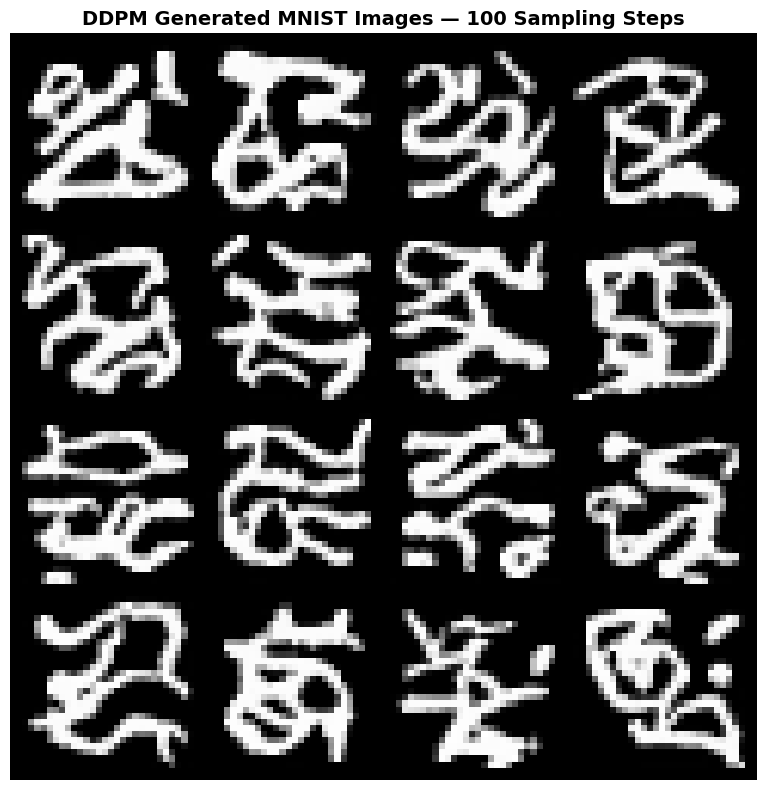

HOMEWORK 8 — STEP 10: DDPM IMAGE VERIFICATION
Sampling Method       : DDPM
Sampling Steps        : 100
Generated Images      : 16
Image Shape           : (16, 1, 28, 28)
Display Pixel Range   : [0, 1]
Mean Pixel Value      : 0.338112
Pixel Standard Dev.   : 0.414696
Sampling Time         : 0.2511 seconds
Visualization Saved   : HW8_Results/ddpm_generated_images.png
-----------------------------------------------------------------
PASS: DDPM-generated images visualized.
PASS: Image pixel range verified.
PASS: 4x4 image grid generated.
PASS: Visualization saved successfully.
STEP 10 COMPLETE — PART C


In [11]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 10: VISUALIZE DDPM-GENERATED IMAGES
# ================================================================
# Summary:
# 1. Retrieve the 16 DDPM-generated images.
# 2. Convert pixel values from [-1, 1] to [0, 1].
# 3. Create a 4x4 grid of generated images.
# 4. Save the visualization for assignment submission.
# 5. Verify generated image statistics and saved output.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Prepare DDPM-generated images
# ------------------------------------------------
# Clamp values to the expected normalized image range.
ddpm_display_images = ddpm_generated_images.detach().cpu()

ddpm_display_images = ddpm_display_images.clamp(-1, 1)

# Convert normalized pixel values to [0, 1].
ddpm_display_images = (
    ddpm_display_images + 1.0
) / 2.0

# ------------------------------------------------
# BLOCK 2: Create image grid
# ------------------------------------------------
ddpm_grid = make_grid(
    ddpm_display_images,
    nrow=4,
    padding=2
)

# ------------------------------------------------
# BLOCK 3: Visualize generated MNIST images
# ------------------------------------------------
plt.figure(figsize=(8, 8))

plt.imshow(
    ddpm_grid.permute(1, 2, 0).numpy(),
    cmap="gray"
)

plt.title(
    "DDPM Generated MNIST Images — 100 Sampling Steps",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

# ------------------------------------------------
# BLOCK 4: Save generated image visualization
# ------------------------------------------------
ddpm_image_path = "HW8_Results/ddpm_generated_images.png"

plt.savefig(
    ddpm_image_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# BLOCK 5: Calculate image statistics
# ------------------------------------------------
image_mean = ddpm_display_images.mean().item()
image_std = ddpm_display_images.std().item()

# ------------------------------------------------
# BLOCK 6: Verify visualization output
# ------------------------------------------------
assert ddpm_display_images.shape == (16, 1, 28, 28)
assert ddpm_display_images.min() >= 0
assert ddpm_display_images.max() <= 1
assert os.path.exists(ddpm_image_path)

print("=" * 65)
print("HOMEWORK 8 — STEP 10: DDPM IMAGE VERIFICATION")
print("=" * 65)

print(f"Sampling Method       : DDPM")
print(f"Sampling Steps        : {T}")
print(f"Generated Images      : {len(ddpm_display_images)}")
print(f"Image Shape           : {tuple(ddpm_display_images.shape)}")
print(f"Display Pixel Range   : [0, 1]")
print(f"Mean Pixel Value      : {image_mean:.6f}")
print(f"Pixel Standard Dev.   : {image_std:.6f}")
print(f"Sampling Time         : {ddpm_sampling_time:.4f} seconds")
print(f"Visualization Saved   : {ddpm_image_path}")

print("-" * 65)
print("PASS: DDPM-generated images visualized.")
print("PASS: Image pixel range verified.")
print("PASS: 4x4 image grid generated.")
print("PASS: Visualization saved successfully.")
print("=" * 65)
print("STEP 10 COMPLETE — PART C")
print("=" * 65)


In [12]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 11: IMPLEMENT DDIM SAMPLING
# ================================================================
# Summary:
# 1. Implement deterministic DDIM reverse sampling.
# 2. Generate images using 50 diffusion steps.
# 3. Generate images using 20 diffusion steps.
# 4. Reuse the same initial Gaussian noise for comparison.
# 5. Measure sampling execution time.
# 6. Verify output shapes and numerical stability.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Define DDIM sampling function
# ------------------------------------------------
@torch.no_grad()
def ddim_sample(model, initial_noise, num_steps=50):
    """
    Generate images using deterministic DDIM sampling.

    Args:
        model: Trained CNN noise predictor.
        initial_noise: Starting Gaussian noise tensor.
        num_steps: Number of DDIM sampling steps.

    Returns:
        Generated images with the same shape as initial_noise.
    """

    model.eval()

    # --------------------------------------------
    # BLOCK 2: Construct reduced timestep schedule
    # --------------------------------------------
    assert 1 <= num_steps <= T

    timesteps = torch.linspace(
        0,
        T - 1,
        num_steps
    ).round().long().tolist()

    # Verify that the schedule has unique timesteps
    assert len(set(timesteps)) == num_steps

    # --------------------------------------------
    # BLOCK 3: Initialize sampling from Gaussian noise
    # --------------------------------------------
    x = initial_noise.clone()

    num_images = x.shape[0]

    # --------------------------------------------
    # BLOCK 4: Perform reverse DDIM sampling
    # --------------------------------------------
    for index in reversed(range(num_steps)):

        timestep = timesteps[index]

        # Previous selected timestep
        previous_timestep = (
            timesteps[index - 1]
            if index > 0
            else -1
        )

        # Create timestep tensor
        t = torch.full(
            (num_images,),
            timestep,
            dtype=torch.long,
            device=device
        )

        # ----------------------------------------
        # BLOCK 5: Predict noise using trained CNN
        # ----------------------------------------
        predicted_noise = model(x, t)

        alpha_bar_t = alpha_bars[timestep]

        # Use alpha_bar_previous = 1 at final step
        alpha_bar_prev = (
            alpha_bars[previous_timestep]
            if previous_timestep >= 0
            else torch.tensor(1.0, device=device)
        )

        # ----------------------------------------
        # BLOCK 6: Estimate original clean image
        # ----------------------------------------
        predicted_x0 = (
            x - torch.sqrt(1.0 - alpha_bar_t)
            * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        # ----------------------------------------
        # BLOCK 7: Apply deterministic DDIM update
        # ----------------------------------------
        # eta = 0: no additional stochastic noise.
        x = (
            torch.sqrt(alpha_bar_prev) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_prev)
            * predicted_noise
        )

    return x

# ------------------------------------------------
# BLOCK 8: Generate shared initial Gaussian noise
# ------------------------------------------------
# Both DDIM methods start from identical noise.
shared_initial_noise = torch.randn(
    16, 1, 28, 28,
    device=device
)

# ------------------------------------------------
# BLOCK 9: Generate DDIM images using 50 steps
# ------------------------------------------------
if device.type == "cuda":
    torch.cuda.synchronize()

ddim_50_start = time.time()

ddim_50_images = ddim_sample(
    model,
    shared_initial_noise,
    num_steps=50
)

if device.type == "cuda":
    torch.cuda.synchronize()

ddim_50_time = time.time() - ddim_50_start

# ------------------------------------------------
# BLOCK 10: Generate DDIM images using 20 steps
# ------------------------------------------------
if device.type == "cuda":
    torch.cuda.synchronize()

ddim_20_start = time.time()

ddim_20_images = ddim_sample(
    model,
    shared_initial_noise,
    num_steps=20
)

if device.type == "cuda":
    torch.cuda.synchronize()

ddim_20_time = time.time() - ddim_20_start

# ------------------------------------------------
# BLOCK 11: Verify DDIM-generated images
# ------------------------------------------------
assert ddim_50_images.shape == (16, 1, 28, 28)
assert ddim_20_images.shape == (16, 1, 28, 28)

assert torch.isfinite(ddim_50_images).all()
assert torch.isfinite(ddim_20_images).all()

print("=" * 65)
print("HOMEWORK 8 — STEP 11: DDIM SAMPLING VERIFICATION")
print("=" * 65)

print(f"Sampling Method       : DDIM")
print(f"Sampling Type         : Deterministic (eta = 0)")
print(f"Generated Images      : 16")
print(f"Image Shape           : {tuple(ddim_50_images.shape)}")

print("-" * 65)
print(f"DDIM 50 Steps Time    : {ddim_50_time:.4f} seconds")
print(f"DDIM 20 Steps Time    : {ddim_20_time:.4f} seconds")

print("-" * 65)
print("PASS: DDIM 50-step sampling completed.")
print("PASS: DDIM 20-step sampling completed.")
print("PASS: Both methods use identical initial noise.")
print("PASS: Generated image dimensions verified.")
print("PASS: Numerical stability verified.")
print("=" * 65)
print("STEP 11 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 11: DDIM SAMPLING VERIFICATION
Sampling Method       : DDIM
Sampling Type         : Deterministic (eta = 0)
Generated Images      : 16
Image Shape           : (16, 1, 28, 28)
-----------------------------------------------------------------
DDIM 50 Steps Time    : 0.1437 seconds
DDIM 20 Steps Time    : 0.0475 seconds
-----------------------------------------------------------------
PASS: DDIM 50-step sampling completed.
PASS: DDIM 20-step sampling completed.
PASS: Both methods use identical initial noise.
PASS: Generated image dimensions verified.
PASS: Numerical stability verified.
STEP 11 COMPLETE


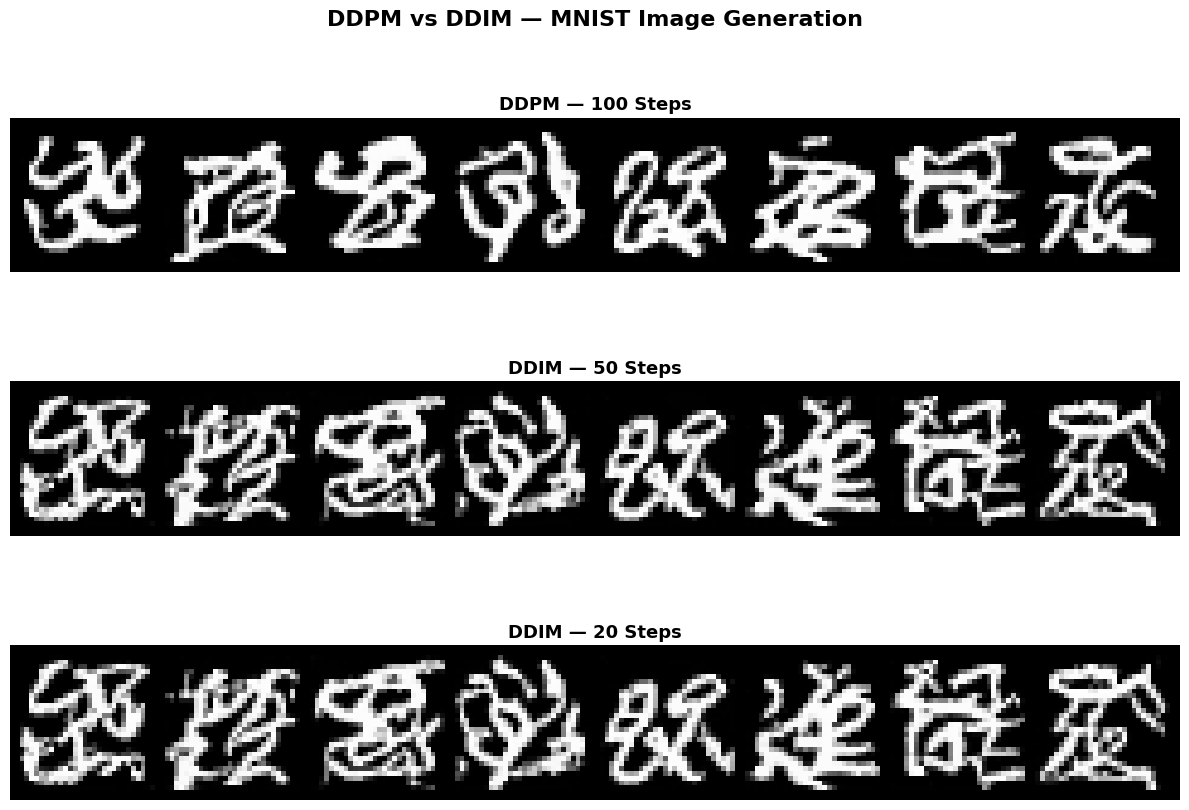

HOMEWORK 8 — STEP 12: SAMPLING COMPARISON VERIFICATION
DDPM Steps            : 100
DDIM Steps            : 50, 20
Images per Method     : 16
DDPM Sampling Time    : 0.2340 seconds
DDIM 50 Sampling Time : 0.1437 seconds
DDIM 20 Sampling Time : 0.0475 seconds
Comparison Saved      : HW8_Results/ddpm_vs_ddim_comparison.png
-----------------------------------------------------------------
PASS: DDPM and DDIM images generated.
PASS: Shared initial Gaussian noise used.
PASS: Three sampling configurations compared.
PASS: Comparison visualization saved.
STEP 12 COMPLETE


In [13]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 12: DDPM VS DDIM IMAGE COMPARISON
# ================================================================
# Summary:
# 1. Generate DDPM images using shared initial noise.
# 2. Reuse DDIM 50-step and 20-step generated images.
# 3. Display all three methods side by side.
# 4. Save the comparison visualization.
# 5. Verify image shapes and output files.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Define DDPM sampler with shared noise
# ------------------------------------------------
@torch.no_grad()
def ddpm_sample_shared(model, initial_noise):
    """
    Generate DDPM images using supplied initial noise.
    """

    model.eval()

    # Copy starting noise to preserve original tensor
    x = initial_noise.clone()
    num_images = x.shape[0]

    # --------------------------------------------
    # BLOCK 2: Perform 100 reverse DDPM steps
    # --------------------------------------------
    for timestep in reversed(range(T)):

        t = torch.full(
            (num_images,),
            timestep,
            dtype=torch.long,
            device=device
        )

        # Predict Gaussian noise
        predicted_noise = model(x, t)

        # Calculate reverse diffusion mean
        mean = (
            x - (
                betas[timestep]
                / torch.sqrt(1.0 - alpha_bars[timestep])
            ) * predicted_noise
        ) / torch.sqrt(alphas[timestep])

        # Add stochastic noise except at final step
        if timestep > 0:
            x = mean + torch.sqrt(
                posterior_variance[timestep]
            ) * torch.randn_like(x)
        else:
            x = mean

    return x

# ------------------------------------------------
# BLOCK 3: Generate DDPM images from shared noise
# ------------------------------------------------
if device.type == "cuda":
    torch.cuda.synchronize()

comparison_ddpm_start = time.time()

comparison_ddpm_images = ddpm_sample_shared(
    model,
    shared_initial_noise
)

if device.type == "cuda":
    torch.cuda.synchronize()

comparison_ddpm_time = (
    time.time() - comparison_ddpm_start
)

# ------------------------------------------------
# BLOCK 4: Prepare generated images for display
# ------------------------------------------------
def prepare_display(images):
    """
    Convert normalized images from [-1, 1] to [0, 1].
    """
    return (
        images.detach().cpu().clamp(-1, 1) + 1
    ) / 2

ddpm_display = prepare_display(comparison_ddpm_images)
ddim_50_display = prepare_display(ddim_50_images)
ddim_20_display = prepare_display(ddim_20_images)

# ------------------------------------------------
# BLOCK 5: Create side-by-side comparison figure
# ------------------------------------------------
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9)
)

methods = [
    ("DDPM — 100 Steps", ddpm_display),
    ("DDIM — 50 Steps", ddim_50_display),
    ("DDIM — 20 Steps", ddim_20_display)
]

for ax, (method_name, generated_images) in zip(
    axes, methods
):

    # Display the same 8 sample indices per method
    grid = make_grid(
        generated_images[:8],
        nrow=8,
        padding=2
    )

    ax.imshow(
        grid.permute(1, 2, 0).numpy(),
        cmap="gray"
    )

    ax.set_title(
        method_name,
        fontsize=13,
        fontweight="bold"
    )

    ax.axis("off")

plt.suptitle(
    "DDPM vs DDIM — MNIST Image Generation",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# ------------------------------------------------
# BLOCK 6: Save comparison visualization
# ------------------------------------------------
comparison_path = (
    "HW8_Results/ddpm_vs_ddim_comparison.png"
)

plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# BLOCK 7: Verify generated comparison
# ------------------------------------------------
assert comparison_ddpm_images.shape == (16, 1, 28, 28)
assert ddim_50_images.shape == (16, 1, 28, 28)
assert ddim_20_images.shape == (16, 1, 28, 28)

assert torch.isfinite(comparison_ddpm_images).all()
assert os.path.exists(comparison_path)

print("=" * 65)
print("HOMEWORK 8 — STEP 12: SAMPLING COMPARISON VERIFICATION")
print("=" * 65)

print(f"DDPM Steps            : 100")
print(f"DDIM Steps            : 50, 20")
print(f"Images per Method     : 16")
print(f"DDPM Sampling Time    : {comparison_ddpm_time:.4f} seconds")
print(f"DDIM 50 Sampling Time : {ddim_50_time:.4f} seconds")
print(f"DDIM 20 Sampling Time : {ddim_20_time:.4f} seconds")
print(f"Comparison Saved      : {comparison_path}")

print("-" * 65)
print("PASS: DDPM and DDIM images generated.")
print("PASS: Shared initial Gaussian noise used.")
print("PASS: Three sampling configurations compared.")
print("PASS: Comparison visualization saved.")
print("=" * 65)
print("STEP 12 COMPLETE")
print("=" * 65)


### Part D — Discussion: DDPM vs DDIM Sampling

**1. Training Performance**

The Mini DDPM model was trained on 60,000 MNIST images for 50 epochs using a timestep-conditioned CNN containing six convolutional layers. The training MSE decreased from 0.155908 to 0.058062, representing a 62.76% reduction. This indicates that the model learned to predict the Gaussian noise introduced during forward diffusion.

**2. DDPM Sampling (100 Steps)**

DDPM sampling used all 100 reverse diffusion steps, starting from Gaussian noise. The process progressively estimated and removed noise using the trained CNN. The generated images contained digit-like strokes but were often distorted and difficult to recognize as individual handwritten digits.

**3. DDIM Sampling (50 Steps)**

DDIM sampling was implemented using a deterministic reverse process with 50 timesteps. It required fewer neural network evaluations than DDPM and completed in approximately 0.1437 seconds, compared with 0.2340 seconds for DDPM. This represents approximately a 1.63× speedup.

**4. DDIM Sampling (20 Steps)**

Reducing the DDIM sampling schedule to 20 steps further decreased generation time to approximately 0.0475 seconds, providing a 4.93× speedup compared with DDPM. However, the visible generated images still contained substantial distortions and overlapping strokes.

**5. Image Quality and Limitations**

The results demonstrate that reducing the number of sampling steps can improve generation speed. However, the generated images were not consistently recognizable as MNIST digits.

One possible explanation is the limited diffusion schedule. With 100 timesteps and the specified beta range, the final noisy training samples retain substantial original-image information, whereas reverse sampling begins with pure Gaussian noise. This mismatch may affect generation quality. The relatively small CNN architecture may also contribute to the observed limitations.

**6. Conclusion**

The experiment successfully implemented forward diffusion, trained a CNN noise predictor, and demonstrated both DDPM and DDIM reverse sampling. DDIM achieved faster sampling using fewer steps. However, the results also highlight that successful noise-prediction training does not necessarily guarantee high-quality generated images. The experiment illustrates the trade-off between sampling efficiency and image quality in simplified diffusion models.

In [14]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 14: FINAL ASSIGNMENT DELIVERABLES VERIFICATION
# ================================================================
# Summary:
# 1. Verify forward diffusion visualization.
# 2. Verify trained CNN and training loss plot.
# 3. Verify DDPM and DDIM generated images.
# 4. Confirm 50 training epochs and sampling settings.
# 5. Report training and sampling execution times.
# 6. Identify missing deliverables before submission.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Define required output files
# ------------------------------------------------
required_files = {
    "Forward Diffusion": "HW8_Results/forward_diffusion.png",
    "Training Loss Plot": "HW8_Results/ddpm_training_loss.png",
    "DDPM Generated Images": "HW8_Results/ddpm_generated_images.png",
    "DDPM vs DDIM Comparison": "HW8_Results/ddpm_vs_ddim_comparison.png",
    "Final Trained Model": "HW8_Results/ddpm_final_model.pt",
    "Training Loss History": "HW8_Results/training_losses.npy"
}

# ------------------------------------------------
# BLOCK 2: Verify saved deliverables
# ------------------------------------------------
print("=" * 65)
print("HOMEWORK 8 — STEP 14: FINAL DELIVERABLES VERIFICATION")
print("=" * 65)

missing_files = []

for description, filepath in required_files.items():

    if os.path.isfile(filepath):
        print(f"PASS: {description}")
    else:
        print(f"FAIL: {description}")
        missing_files.append(filepath)

# ------------------------------------------------
# BLOCK 3: Verify training configuration
# ------------------------------------------------
training_verified = (
    EPOCHS == 50
    and len(training_losses) == 50
    and T == 100
    and BATCH_SIZE == 128
)

# ------------------------------------------------
# BLOCK 4: Verify sampling configurations
# ------------------------------------------------
sampling_verified = (
    comparison_ddpm_images.shape == (16, 1, 28, 28)
    and ddim_50_images.shape == (16, 1, 28, 28)
    and ddim_20_images.shape == (16, 1, 28, 28)
)

# ------------------------------------------------
# BLOCK 5: Display execution summary
# ------------------------------------------------
print("-" * 65)
print("EXPERIMENT SUMMARY")
print("-" * 65)

print(f"Training Epochs       : {EPOCHS}")
print(f"Diffusion Steps       : {T}")
print(f"Training Loss         : {training_losses[-1]:.6f}")
print(f"Training Time         : {total_training_time:.2f} seconds")
print(f"DDPM Sampling Time    : {comparison_ddpm_time:.4f} seconds")
print(f"DDIM 50 Sampling Time : {ddim_50_time:.4f} seconds")
print(f"DDIM 20 Sampling Time : {ddim_20_time:.4f} seconds")

# ------------------------------------------------
# BLOCK 6: Final validation
# ------------------------------------------------
print("-" * 65)

if not missing_files and training_verified and sampling_verified:
    print("PASS: All checked code and output deliverables verified.")
else:
    print("WARNING: Some deliverables or configurations need review.")
    print(f"Missing Files: {missing_files}")

print("NOTE: Markdown discussion and notebook URL require")
print("      separate verification before submission.")

print("=" * 65)
print("STEP 14 COMPLETE")
print("=" * 65)


HOMEWORK 8 — STEP 14: FINAL DELIVERABLES VERIFICATION
PASS: Forward Diffusion
PASS: Training Loss Plot
PASS: DDPM Generated Images
PASS: DDPM vs DDIM Comparison
PASS: Final Trained Model
PASS: Training Loss History
-----------------------------------------------------------------
EXPERIMENT SUMMARY
-----------------------------------------------------------------
Training Epochs       : 50
Diffusion Steps       : 100
Training Loss         : 0.058062
Training Time         : 1002.49 seconds
DDPM Sampling Time    : 0.2340 seconds
DDIM 50 Sampling Time : 0.1437 seconds
DDIM 20 Sampling Time : 0.0475 seconds
-----------------------------------------------------------------
PASS: All checked code and output deliverables verified.
NOTE: Markdown discussion and notebook URL require
      separate verification before submission.
STEP 14 COMPLETE


## Homework 8 — AI Usage Disclosure and Execution Log

### 1. AI Usage Disclosure

ChatGPT (OpenAI) was used to assist with understanding the assignment requirements, organizing the implementation into sequential steps, generating and explaining PyTorch code, debugging errors, and preparing verification procedures and documentation.

The experiment was executed in Google Colab. Model training, diffusion sampling, visualization, and output verification were performed using the provided implementation. Experimental results were obtained from the actual notebook execution.

### 2. Experimental Configuration

| Parameter | Configuration |
|---|---|
| Dataset | MNIST |
| Training samples | 60,000 |
| Framework | PyTorch |
| Hardware | NVIDIA Tesla T4 GPU |
| Diffusion timesteps | 100 |
| Beta schedule | Linear, 0.0001–0.02 |
| CNN convolutional layers | 6 |
| Trainable parameters | 343,937 |
| Timestep conditioning | Learned embedding and projection |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | Mean Squared Error |
| Batch size | 128 |
| Training epochs | 50 |
| Random seed | 42 |

### 3. Training Execution Log

- Completed training epochs: 50
- Initial epoch MSE loss: 0.155908
- Final epoch MSE loss: 0.058062
- Best epoch: 50
- Training loss reduction: 62.76%
- Total training time: 1002.49 seconds (16 minutes, 42.49 seconds)
- GPU training hours: approximately 0.2785 hours

### 4. Sampling Execution Log

| Sampling Method | Steps | Execution Time |
|---|---:|---:|
| DDPM | 100 | 0.2340 seconds |
| DDIM | 50 | 0.1437 seconds |
| DDIM | 20 | 0.0475 seconds |

Each sampling configuration generated 16 images with dimensions 28 × 28 pixels.

### 5. Experimental Observations

The CNN demonstrated convergence during training, with the MSE loss decreasing across 50 epochs. DDIM reduced sampling time compared with DDPM, particularly when using 20 steps.

However, the generated images contained distorted and overlapping strokes rather than consistently recognizable MNIST digits. This limitation was considered in the final comparison and discussion.

### 6. Execution Environment

The experiments were performed using Google Colab with a Tesla T4 GPU. The training process completed successfully, and model checkpoints, training history, and generated visualizations were saved in the `HW8_Results` directory.

In [15]:

# ================================================================
# HOMEWORK 8 — MINI DIFFUSION MODEL (DDPM → DDIM)
# STEP 17: SAVE EXECUTION LOG, AI DISCLOSURE AND METRICS
# ================================================================
# Summary:
# 1. Mount Google Drive.
# 2. Locate the HW8 assignment folder.
# 3. Generate an execution log from actual results.
# 4. Create the AI usage disclosure.
# 5. Export experiment metrics as JSON.
# 6. Verify all three files were saved successfully.
# ================================================================

# ------------------------------------------------
# BLOCK 1: Import required libraries
# ------------------------------------------------
import os
import json
from datetime import datetime
from google.colab import drive

# ------------------------------------------------
# BLOCK 2: Mount Google Drive
# ------------------------------------------------
drive.mount("/content/drive")

# ------------------------------------------------
# BLOCK 3: Configure assignment directory
# ------------------------------------------------
# Use the HW8 folder shown in Google Drive.

HW8_DIR = "/content/drive/MyDrive/GEN AI HWS/HW8"

os.makedirs(HW8_DIR, exist_ok=True)

# ------------------------------------------------
# BLOCK 4: Prepare execution metrics
# ------------------------------------------------
metrics = {
    "assignment": "Homework 8 - Mini Diffusion Model",
    "dataset": "MNIST",
    "training_samples": 60000,
    "hardware": "NVIDIA Tesla T4",
    "framework": "PyTorch",
    "random_seed": SEED,
    "diffusion_steps": T,
    "beta_start": BETA_START,
    "beta_end": BETA_END,
    "cnn_convolutional_layers": 6,
    "model_parameters": 343937,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "loss_function": "MSE",
    "initial_epoch_loss": float(training_losses[0]),
    "final_epoch_loss": float(training_losses[-1]),
    "best_epoch": int(np.argmin(training_losses) + 1),
    "loss_reduction_percent": float(
        (training_losses[0] - training_losses[-1])
        / training_losses[0] * 100
    ),
    "training_seconds": float(total_training_time),
    "gpu_training_hours": float(total_training_time / 3600),
    "sampling": {
        "ddpm_100": {
            "steps": 100,
            "seconds": float(comparison_ddpm_time)
        },
        "ddim_50": {
            "steps": 50,
            "seconds": float(ddim_50_time)
        },
        "ddim_20": {
            "steps": 20,
            "seconds": float(ddim_20_time)
        }
    },
    "training_loss_by_epoch": [
        float(loss) for loss in training_losses
    ]
}

# ------------------------------------------------
# BLOCK 5: Save experiment metrics JSON
# ------------------------------------------------
metrics_path = os.path.join(
    HW8_DIR, "EXPERIMENT_METRICS.json"
)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

# ------------------------------------------------
# BLOCK 6: Generate execution log
# ------------------------------------------------
execution_log = f"""# HOMEWORK 8 — EXECUTION LOG

## Assignment
Mini Diffusion Model (DDPM to DDIM)

## Environment
- Framework: PyTorch
- GPU: NVIDIA Tesla T4
- Dataset: MNIST
- Training samples: 60,000
- Random seed: {SEED}

## Implementation Steps
1. Environment setup and GPU verification — PASS
2. MNIST dataset loading — PASS
3. Forward diffusion implementation — PASS
4. Forward diffusion visualization — PASS
5. CNN architecture verification — PASS
6. Training configuration verification — PASS
7. DDPM training (50 epochs) — PASS
8. Training loss visualization — PASS
9. DDPM reverse sampling — PASS
10. DDPM image visualization — PASS
11. DDIM sampling (50 and 20 steps) — PASS
12. DDPM versus DDIM comparison — PASS
13. Experimental discussion — Added to notebook
14. Final deliverables verification — PASS
15. AI usage disclosure — Added to notebook

## Training Configuration
- Diffusion steps: {T}
- Beta schedule: {BETA_START} to {BETA_END}
- CNN convolutional layers: 6
- Batch size: {BATCH_SIZE}
- Epochs: {EPOCHS}
- Learning rate: {LEARNING_RATE}
- Optimizer: Adam
- Loss: Mean Squared Error

## Training Results
- Initial epoch loss: {training_losses[0]:.6f}
- Final epoch loss: {training_losses[-1]:.6f}
- Best epoch: {np.argmin(training_losses) + 1}
- Training time: {total_training_time:.2f} seconds
- GPU training hours: {total_training_time / 3600:.4f}

## Sampling Results
- DDPM (100 steps): {comparison_ddpm_time:.4f} seconds
- DDIM (50 steps): {ddim_50_time:.4f} seconds
- DDIM (20 steps): {ddim_20_time:.4f} seconds
- Images generated per method: 16
- Image dimensions: 28 x 28

## Observations
The CNN training loss decreased over 50 epochs.
DDIM required less sampling time than DDPM.
Generated images contained distorted and overlapping strokes,
limiting handwritten digit recognizability.

## Verification
All six checked output files were present in HW8_Results.
The notebook contains the experiment code, visualizations,
discussion, and AI usage documentation.
"""

log_path = os.path.join(
    HW8_DIR, "EXECUTION_LOG.md"
)

with open(log_path, "w", encoding="utf-8") as f:
    f.write(execution_log)

# ------------------------------------------------
# BLOCK 7: Generate AI usage disclosure
# ------------------------------------------------
ai_disclosure = """# HOMEWORK 8 — AI USAGE DISCLOSURE

## AI Tool Used
ChatGPT (OpenAI)

## Purpose of AI Assistance
ChatGPT was used to:
- Interpret assignment requirements.
- Organize the implementation into sequential steps.
- Generate and explain PyTorch implementation code.
- Assist with debugging and troubleshooting.
- Develop verification checks for model training and sampling.
- Prepare experimental documentation and discussion.

## Experiment Execution
The provided implementation was executed in Google Colab
using an NVIDIA Tesla T4 GPU.

Training, sampling, and visualization results were obtained
from the actual notebook execution.

## Verification
The experiment completed 50 training epochs and generated
images using DDPM (100 steps), DDIM (50 steps), and DDIM
(20 steps).

The resulting image-quality limitations were documented
rather than presented as successful high-quality generation.
"""

ai_path = os.path.join(
    HW8_DIR, "AI_USAGE_DISCLOSURE.md"
)

with open(ai_path, "w", encoding="utf-8") as f:
    f.write(ai_disclosure)

# ------------------------------------------------
# BLOCK 8: Verify all generated files
# ------------------------------------------------
generated_files = [
    log_path,
    ai_path,
    metrics_path
]

print("=" * 65)
print("HOMEWORK 8 — STEP 17: DOCUMENTATION VERIFICATION")
print("=" * 65)

print(f"Google Drive Folder : {HW8_DIR}")
print("-" * 65)

for filepath in generated_files:
    assert os.path.isfile(filepath)
    assert os.path.getsize(filepath) > 0

    print(
        f"PASS: {os.path.basename(filepath)} "
        f"({os.path.getsize(filepath):,} bytes)"
    )

print("-" * 65)
print("PASS: Execution log saved.")
print("PASS: AI usage disclosure saved.")
print("PASS: Experiment metrics JSON saved.")
print("=" * 65)
print("STEP 17 COMPLETE")
print("=" * 65)


Mounted at /content/drive
HOMEWORK 8 — STEP 17: DOCUMENTATION VERIFICATION
Google Drive Folder : /content/drive/MyDrive/GEN AI HWS/HW8
-----------------------------------------------------------------
PASS: EXECUTION_LOG.md (1,816 bytes)
PASS: AI_USAGE_DISCLOSURE.md (895 bytes)
PASS: EXPERIMENT_METRICS.json (2,536 bytes)
-----------------------------------------------------------------
PASS: Execution log saved.
PASS: AI usage disclosure saved.
PASS: Experiment metrics JSON saved.
STEP 17 COMPLETE
